In [ ]:
!pip install transformers

In [ ]:
pip install protobuf==3.20.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 16.3 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 5.29.6
    Uninstalling protobuf-5.29.6:
      Successfully uninstalled protobuf-5.29.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-cloud-spanner 3.66.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-datastore 2.24.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-appengine-logging 1.9.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
grpc-google-iam-v1 0.14.4 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.
google-cloud-firestore 2.27.0 requires protobuf<8.0.0,>=4.25.8, but you have protobuf 3.20.3 which is incompatible.


In [ ]:
import os
import pickle
import random
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from torch.optim import AdamW
from torch.utils.data import (DataLoader, RandomSampler, SequentialSampler, TensorDataset)
from transformers import BertModel, BertTokenizer
from transformers.optimization import get_linear_schedule_with_warmup
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['CUDA_LAUNCH_BLOCKING'] = '1'

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f'There are {torch.cuda.device_count()} GPU(s) available.')
    print('Device name:', torch.cuda.get_device_name(0))

else:
    print('No GPU available, using the CPU instead.')
    device = torch.device("cpu")

There are 1 GPU(s) available.
Device name: NVIDIA A100-SXM4-40GB


In [ ]:
# load data from drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# --- TẢI VÀ TIỀN XỬ LÝ DỮ LIỆU ---
dataset_file_path = '/content/drive/MyDrive/Bert/Data/booking_sent_analysis_data.pkl'

# Ánh xạ nhãn gốc (dạng chuỗi điểm) sang số nguyên từ 0-9
encoded_label_dict = {str(i): i - 1 for i in range(1, 11)}

with open(dataset_file_path, 'rb') as pf:
    loaded_data = pickle.load(pf)
    review_data_records = loaded_data['review_data_records']
    original_labels_str = loaded_data['labels']

    # Chuyển nhãn sang số nguyên (0-9)
    original_labels_int = [encoded_label_dict[str(int(float(label)))] for label in original_labels_str]

    # Vì các nhãn thực tế có thể không đủ 10 lớp (ví dụ chỉ từ 5-10 điểm),
    # chúng ta cần ánh xạ lại chúng về một dãy bắt đầu từ 0.
    unique_labels_sorted = sorted(list(set(original_labels_int)))
    remapping_dict = {old_label: new_label for new_label, old_label in enumerate(unique_labels_sorted)}
    print(f"Ánh xạ lại các nhãn: {remapping_dict}")

    # Nhãn cuối cùng để huấn luyện mô hình, bắt đầu từ 0
    final_labels = [remapping_dict[l] for l in original_labels_int]

    # Tách các thành phần dữ liệu
    hotel_other_info = [record[0] for record in review_data_records]
    textual_review_docs = [record[1] for record in review_data_records]
    review_other_info = [record[2] for record in review_data_records]

    print(f'\nTổng số bản ghi review đã tải: [{len(textual_review_docs)}]')
    NUM_CLASSES = len(set(final_labels))
    print(f'Tổng số lớp (sau khi ánh xạ): [{NUM_CLASSES}]')
    print(f"Các nhãn mới: {sorted(list(set(final_labels)))}")
# Sau phần:
# review_data_records = loaded_data['review_data_records']
# original_labels_str = loaded_data['labels']

print("\n=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===")
for i in range(min(5, len(review_data_records))):
    hotel_info = review_data_records[i][0]          # Thông tin khách sạn (dict/list/str)
    review_text = review_data_records[i][1]         # Nội dung đánh giá văn bản
    other_info = review_data_records[i][2]          # Thông tin khác của review

    print(f"\nMẫu {i+1}:")
    print("  - Nhãn gốc (string):", original_labels_str[i])
    print("  - Nhãn đã mã hóa (sau remap):", final_labels[i])
    print("  - Hotel other info:", hotel_info)
    print("  - Textual review (nội dung đánh giá):")
    print("   ", review_text[:300] + "..." if len(review_text) > 300 else review_text)
    print("  - Review other info:", other_info)
    print("-" * 100)


Ánh xạ lại các nhãn: {4: 0, 5: 1, 6: 2, 7: 3, 8: 4, 9: 5}

Tổng số bản ghi review đã tải: [41136]
Tổng số lớp (sau khi ánh xạ): [6]
Các nhãn mới: [0, 1, 2, 3, 4, 5]

=== 5 MẪU ĐẦU TIÊN CỦA DỮ LIỆU ===

Mẫu 1:
  - Nhãn gốc (string): 10
  - Nhãn đã mã hóa (sau remap): 5
  - Hotel other info: [8.4, 7.9, 7.9, 8.0, 8.0, 8.5, 8.2]
  - Textual review (nội dung đánh giá):
    xuất_sắc tốt về chất_lượng phòng cảm_quan thấy ổn_áp
  - Review other info: [408, 1, 3]
----------------------------------------------------------------------------------------------------

Mẫu 2:
  - Nhãn gốc (string): 8
  - Nhãn đã mã hóa (sau remap): 3
  - Hotel other info: [8.5, 7.7, 8.0, 8.0, 8.3, 8.9, 8.5]
  - Textual review (nội dung đánh giá):
    tiếc là đi vào ngày trời âm_u biển động mà con lớn lại sốt nên không đi chơi tốt nhiều chỗ nghỉ gần bãi biển đi bộ_xíu là tới
  - Review other info: [1205, 3, 0]
----------------------------------------------------------------------------------------------------

Mẫu 3:


In [ ]:
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
from transformers import AutoTokenizer
import torch

tokenizer = AutoTokenizer.from_pretrained("Geotrend/distilbert-base-vi-cased")   #thay đổi mô hình tokenizer

# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
# tokenizer = BertTokenizer.from_pretrained("trituenhantaoio/bert-base-vietnamese-uncased")

# Mã hóa văn bản và xác định độ dài tối đa
encoded_textual_review_docs = [tokenizer.encode(doc, add_special_tokens=True) for doc in textual_review_docs]
max_len_auto = max(len(sent) for sent in encoded_textual_review_docs)
MAX_LEN = 254
print('Độ dài tối đa của chuỗi (MAX_LEN): ', MAX_LEN)

# Thiết lập kích thước batch
BATCH_SIZE = 8

# Kết hợp tất cả dữ liệu thành một danh sách duy nhất
data = []
for i in range(len(textual_review_docs)):
    data.append(
        (hotel_other_info[i], encoded_textual_review_docs[i], review_other_info[i])
    )


# Sửa hàm preprocessing_for_bert để xử lý pre_encoded_ids là list[int] (token IDs đã mã hóa)
def preprocessing_for_bert(data_batch, max_length=512):
    """Chuẩn bị dữ liệu cho mô hình BERT: padding token IDs và tạo attention masks."""
    hotel_infos = []
    review_infos = []
    input_ids_list = []
    attention_masks_list = []

    for hotel_info, pre_encoded_ids, review_info in data_batch:
        hotel_infos.append(hotel_info)
        review_infos.append(review_info)

        # Padding token IDs đến max_length
        padded_ids = pre_encoded_ids + [tokenizer.pad_token_id] * (max_length - len(pre_encoded_ids))
        padded_ids = padded_ids[:max_length]  # Cắt nếu dài hơn

        input_ids_list.append(padded_ids)

        # Tạo attention mask: 1 cho token thực, 0 cho padding
        mask = [1 if token != tokenizer.pad_token_id else 0 for token in padded_ids]
        attention_masks_list.append(mask)

    # Chuyển sang tensor
    hotel_infos_tensor = torch.tensor(hotel_infos, dtype=torch.float32)
    review_infos_tensor = torch.tensor(review_infos, dtype=torch.float32)
    inputs_tensor = torch.tensor(input_ids_list, dtype=torch.long)
    masks_tensor = torch.tensor(attention_masks_list, dtype=torch.long)

    return hotel_infos_tensor, review_infos_tensor, inputs_tensor, masks_tensor

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/104k [00:00<?, ?B/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (517 > 512). Running this sequence through the model will result in indexing errors


Độ dài tối đa của chuỗi (MAX_LEN):  254


In [ ]:
# --- PHÂN CHIA VÀ CHUẨN HÓA DỮ LIỆU ---
# Phân chia tập dữ liệu thành train, validation và test
X_train, X_test, y_train, y_test = train_test_split(data, final_labels, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

print(f'Kích thước tập huấn luyện: [{len(X_train)}]')
print(f'Kích thước tập validation: [{len(X_val)}]')
print(f'Kích thước tập kiểm tra: [{len(X_test)}]')

# Tách các đặc trưng số để chuẩn hóa
X_train_hotel_info = np.array([item[0] for item in X_train])
X_val_hotel_info = np.array([item[0] for item in X_val])
X_test_hotel_info = np.array([item[0] for item in X_test])

X_train_review_info = np.array([item[2] for item in X_train])
X_val_review_info = np.array([item[2] for item in X_val])
X_test_review_info = np.array([item[2] for item in X_test])

# Khởi tạo và fit StandardScaler CHỈ trên tập train
scaler_hotel = StandardScaler().fit(X_train_hotel_info)
scaler_review = StandardScaler().fit(X_train_review_info)

# Áp dụng chuẩn hóa cho cả ba tập
X_train_hotel_scaled = scaler_hotel.transform(X_train_hotel_info)
X_val_hotel_scaled = scaler_hotel.transform(X_val_hotel_info)
X_test_hotel_scaled = scaler_hotel.transform(X_test_hotel_info)

X_train_review_scaled = scaler_review.transform(X_train_review_info)
X_val_review_scaled = scaler_review.transform(X_val_review_info)
X_test_review_scaled = scaler_review.transform(X_test_review_info)

# Cập nhật lại dữ liệu với các giá trị đã được chuẩn hóa
for i in range(len(X_train)):
    X_train[i] = (X_train_hotel_scaled[i].tolist(), X_train[i][1], X_train_review_scaled[i].tolist())
for i in range(len(X_val)):
    X_val[i] = (X_val_hotel_scaled[i].tolist(), X_val[i][1], X_val_review_scaled[i].tolist())
for i in range(len(X_test)):
    X_test[i] = (X_test_hotel_scaled[i].tolist(), X_test[i][1], X_test_review_scaled[i].tolist())

print("Hoàn tất chuẩn hóa dữ liệu số.")

# Áp dụng hàm tiền xử lý để tạo tensor cho mô hình
train_hotel_info, train_review_info, train_inputs, train_masks = preprocessing_for_bert(X_train)
val_hotel_info, val_review_info, val_inputs, val_masks = preprocessing_for_bert(X_val)
test_hotel_info, test_review_info, test_inputs, test_masks = preprocessing_for_bert(X_test)

Kích thước tập huấn luyện: [27971]
Kích thước tập validation: [4937]
Kích thước tập kiểm tra: [8228]
Hoàn tất chuẩn hóa dữ liệu số.


In [ ]:
# --- TẠO DATALOADER ---
# Chuyển nhãn sang tensor
train_labels = torch.tensor(y_train)
val_labels = torch.tensor(y_val)
test_labels = torch.tensor(y_test)

# Tạo DataLoader cho tập huấn luyện
train_data = TensorDataset(train_hotel_info, train_review_info, train_inputs, train_masks, train_labels)
train_sampler = RandomSampler(train_data)
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=BATCH_SIZE)

# Tạo DataLoader cho tập validation
val_data = TensorDataset(val_hotel_info, val_review_info, val_inputs, val_masks, val_labels)
val_sampler = SequentialSampler(val_data)
val_dataloader = DataLoader(val_data, sampler=val_sampler, batch_size=BATCH_SIZE)

# Tạo DataLoader cho tập kiểm tra
test_data = TensorDataset(test_hotel_info, test_review_info, test_inputs, test_masks, test_labels)
test_sampler = SequentialSampler(test_data)
test_dataloader = DataLoader(test_data, sampler=test_sampler, batch_size=BATCH_SIZE)

In [ ]:
# --- ĐỊNH NGHĨA MÔ HÌNH ---
from transformers import AutoModel
import torch.nn as nn
class DistilBERTClassifier(nn.Module):
    """
    Mô hình phân loại kết hợp BERT cho văn bản và các lớp Linear cho đặc trưng số.
    """
    def __init__(self, freeze_backbone=False):
        super(DistilBERTClassifier, self).__init__()

        # Định nghĩa kích thước cho các đặc trưng số
        HOTEL_INFO_DIM = 7  # 7 đặc trưng về khách sạn
        REVIEW_INFO_DIM = 3 # 3 đặc trưng về review
        HOTEL_EMBED_DIM = 32
        REVIEW_EMBED_DIM = 16

        # Mô hình BERT
        # self.bert = BertModel.from_pretrained('trituenhantaoio/bert-base-vietnamese-uncased')

        self.backbone = AutoModel.from_pretrained("Geotrend/distilbert-base-vi-cased") #thay đổi mô hình
        # Lớp embedding cho các đặc trưng số
        self.hotel_info_embedder = nn.Linear(HOTEL_INFO_DIM, HOTEL_EMBED_DIM)
        self.review_info_embedder = nn.Linear(REVIEW_INFO_DIM, REVIEW_EMBED_DIM)

        # Lớp phân loại cuối cùng
        # Đầu vào = BERT output (768) + hotel_embed (32) + review_embed (16)
        D_in = 768 + HOTEL_EMBED_DIM + REVIEW_EMBED_DIM
        H = 128 # Kích thước lớp ẩn
        D_out = NUM_CLASSES

        self.classifier = nn.Sequential(
            nn.Linear(D_in, H),
            nn.ReLU(),
            nn.Dropout(0.2), # Chống overfitting
            nn.Linear(H, D_out)
        )

        # Tùy chọn đóng băng các trọng số của BERT để chỉ huấn luyện lớp phân loại
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False

    def forward(self, hotel_info, review_info, input_ids, attention_mask):
        # Lấy output từ BERT, chỉ cần embedding của token [CLS]
        outputs = self.backbone(input_ids=input_ids, attention_mask=attention_mask)
        last_hidden_state_cls = outputs[0][:, 0, :]

        # Tạo embedding cho các đặc trưng số
        hotel_embedding = self.hotel_info_embedder(hotel_info)
        review_embedding = self.review_info_embedder(review_info)

        # Kết hợp tất cả các embedding
        combined_features = torch.cat([last_hidden_state_cls, hotel_embedding, review_embedding], dim=1)

        # Đưa qua lớp phân loại để có được logits
        logits = self.classifier(combined_features)
        return logits

In [ ]:
# --- THIẾT LẬP HUẤN LUYỆN ---
def initialize_model(epochs=4):
    """Khởi tạo mô hình, optimizer và scheduler."""
    bert_classifier = DistilBERTClassifier(freeze_backbone=False)
    bert_classifier.to(device)

    # Optimizer AdamW với các siêu tham số được đề xuất
    optimizer = AdamW(bert_classifier.parameters(),
                      lr=1e-5,  # Tốc độ học
                      eps=1e-8, # Epsilon
                      weight_decay=0.01) # Giúp chống overfitting

    # Scheduler để điều chỉnh learning rate trong quá trình huấn luyện
    total_steps = len(train_dataloader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer,
                                                num_warmup_steps=0,
                                                num_training_steps=total_steps)
    return bert_classifier, optimizer, scheduler

def set_seed(seed_value=42):
    """Cài đặt seed để đảm bảo kết quả có thể tái lập."""
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)

In [ ]:
# --- CÁC HÀM HUẤN LUYỆN VÀ ĐÁNH GIÁ ---
def train(model, train_dataloader, val_dataloader=None, epochs=4, evaluation=False):
    """Hàm huấn luyện mô hình."""
    print("Bắt đầu huấn luyện...\n")
    for epoch_i in range(epochs):
        # --- Vòng lặp huấn luyện ---
        print(f"{'Epoch':^7} | {'Batch':^7} | {'Train Loss':^12} | {'Val Loss':^10} | {'Val Acc':^9} | {'Elapsed':^9}")
        print("-" * 70)

        t0_epoch, t0_batch = time.time(), time.time()
        total_loss, batch_loss, batch_counts = 0, 0, 0
        model.train()

        for step, batch in enumerate(train_dataloader):
            batch_counts += 1
            # Đưa dữ liệu batch lên GPU
            b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)

            model.zero_grad()
            logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

            loss = loss_fn(logits, b_labels)
            batch_loss += loss.item()
            total_loss += loss.item()

            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0) # Chống bùng nổ gradient

            optimizer.step()
            scheduler.step()

            if (step % 20 == 0 and step != 0) or (step == len(train_dataloader) - 1):
                time_elapsed = time.time() - t0_batch
                print(f"{epoch_i + 1:^7} | {step:^7} | {batch_loss / batch_counts:^12.6f} | {'-':^10} | {'-':^9} | {time_elapsed:^9.2f}")
                batch_loss, batch_counts = 0, 0
                t0_batch = time.time()

        avg_train_loss = total_loss / len(train_dataloader)
        print("-" * 70)

        # --- Vòng lặp đánh giá (Validation) ---
        if evaluation:
            val_loss, val_accuracy = evaluate(model, val_dataloader)
            time_elapsed = time.time() - t0_epoch
            print(f"{epoch_i + 1:^7} | {'-':^7} | {avg_train_loss:^12.6f} | {val_loss:^10.6f} | {val_accuracy:^9.2f} | {time_elapsed:^9.2f}")
            print("-" * 70)
        print("\n")

    print("Hoàn tất huấn luyện!")


def evaluate(model, val_dataloader):
    """Đánh giá hiệu suất mô hình trên tập validation."""
    model.eval()
    val_accuracy = []
    val_loss = []

    for batch in val_dataloader:
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask, b_labels = tuple(t.to(device) for t in batch)
        with torch.no_grad():
            logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)

        loss = loss_fn(logits, b_labels)
        val_loss.append(loss.item())

        preds = torch.argmax(logits, dim=1).flatten()
        accuracy = (preds == b_labels).cpu().numpy().mean() * 100
        val_accuracy.append(accuracy)

    val_loss = np.mean(val_loss)
    val_accuracy = np.mean(val_accuracy)
    return val_loss, val_accuracy


def bert_predict(model, test_dataloader):
    """Dự đoán nhãn cho tập dữ liệu kiểm tra."""
    model.eval()
    all_logits = []

    for batch in test_dataloader:
        # Tập test không có nhãn, chỉ lấy 4 phần tử đầu
        b_hotel_info, b_review_info, b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:4]
        with torch.no_grad():
            logits = model(b_hotel_info, b_review_info, b_input_ids, b_attn_mask)
        all_logits.append(logits)

    all_logits = torch.cat(all_logits, dim=0)
    probs = F.softmax(all_logits, dim=1).cpu().numpy()
    return probs


def compute_accuracy_performances(pred, labels):
    """Tính toán các chỉ số đánh giá."""
    accuracy = accuracy_score(y_true=labels, y_pred=pred)
    recall = recall_score(y_true=labels, y_pred=pred, average='weighted')
    precision = precision_score(y_true=labels, y_pred=pred, average='weighted')
    f1 = f1_score(y_true=labels, y_pred=pred, average='weighted')
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [ ]:
# --- XỬ LÝ MẤT CÂN BẰNG LỚP VÀ BẮT ĐẦU HUẤN LUYỆN ---
import time
import torch
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup
# Giả sử bạn đã định nghĩa trước các hàm/variables này:
# - set_seed(seed)
# - initialize_model(epochs, lr=..., freeze_backbone=...)
# - train(model, train_dataloader, val_dataloader, epochs, evaluation=True)
# - device, train_dataloader, val_dataloader, NUM_CLASSES
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Trọng số các lớp đã tính toán: {weights_tensor}")
# Khởi tạo hàm loss với trọng số để xử lý mất cân bằng dữ liệu
loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)
print("Sử dụng CrossEntropyLoss với trọng số.")

EPOCHS = 5
print("=" * 70)
print(f"BẮT ĐẦU HUẤN LUYỆN DistilBERTClassifier")
print(f"- Epochs: {EPOCHS}")
print(f"- Device: {device}")
print(f"- Số mẫu train: {len(train_dataloader.dataset)}")
print(f"- Batch size: {train_dataloader.batch_size}")
print("=" * 70)
set_seed(42)
start_total_time = time.time()
# Khởi tạo model, optimizer, scheduler
distil_classifier, optimizer, scheduler = initialize_model(
    epochs=EPOCHS,
)
# In thông tin model để debug
print(f"Model parameters: {sum(p.numel() for p in distil_classifier.parameters() if p.requires_grad):,}")
print(f"Trainable parameters: {sum(p.numel() for p in distil_classifier.parameters() if p.requires_grad):,}")
print("-" * 70)
# Chạy huấn luyện (giả sử hàm train sử dụng loss_fn, nếu không thì cần truyền loss_fn vào train)
train(
    distil_classifier,
    train_dataloader,
    val_dataloader,
    epochs=EPOCHS,
    evaluation=True
)
# Kết thúc đo thời gian
total_time = time.time() - start_total_time
print(f"\n{'='*60}")
print(f"TỔNG THỜI GIAN HUẤN LUYỆN: {total_time:.2f} giây")
print(f" ≈ {total_time/60:.2f} phút")
print(f" ≈ {total_time/3600:.2f} giờ")
print('='*60)
# Giải phóng bộ nhớ GPU (nếu dùng CUDA)
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Đã clear GPU cache")

Trọng số các lớp đã tính toán: tensor([6.3083, 7.5556, 2.8391, 1.1565, 0.8467, 0.3020], device='cuda:0')
Sử dụng CrossEntropyLoss với trọng số.
BẮT ĐẦU HUẤN LUYỆN DistilBERTClassifier
- Epochs: 5
- Device: cuda
- Số mẫu train: 27971
- Batch size: 8


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: Geotrend/distilbert-base-vi-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model parameters: 56,486,854
Trainable parameters: 56,486,854
----------------------------------------------------------------------
Bắt đầu huấn luyện...

 Epoch  |  Batch  |  Train Loss  |  Val Loss  |  Val Acc  |  Elapsed 
----------------------------------------------------------------------
   1    |   20    |   1.718984   |     -      |     -     |   2.22   
   1    |   40    |   1.738135   |     -      |     -     |   2.05   
   1    |   60    |   1.692205   |     -      |     -     |   2.05   
   1    |   80    |   1.741775   |     -      |     -     |   2.07   
   1    |   100   |   1.710700   |     -      |     -     |   2.07   
   1    |   120   |   1.708104   |     -      |     -     |   2.05   
   1    |   140   |   1.684551   |     -      |     -     |   2.05   
   1    |   160   |   1.506073   |     -      |     -     |   2.05   
   1    |   180   |   1.608177   |     -      |     -     |   2.05   
   1    |   200   |   1.354533   |     -      |     -     |   2.10   
   

In [ ]:
# --- Dự đoán trên tập Test và Đánh giá cuối cùng ---
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

def distil_predict(model, test_dataloader):
    """
    Thực hiện dự đoán trên tập test với DistilBERTClassifier.

    Args:
        model: DistilBERTClassifier đã được load và .to(device)
        test_dataloader: DataLoader cho tập test (batch gồm input_ids, attention_mask, [labels])

    Returns:
        probs: numpy array shape (n_samples, n_classes) - xác suất softmax
    """
    model.eval()
    all_logits = []

    with torch.no_grad():
        for batch in test_dataloader:
            # Lấy 2 phần tử đầu tiên: input_ids và attention_mask
            # (nếu batch có labels thì bỏ qua phần labels ở đây)
            b_input_ids, b_attn_mask = tuple(t.to(device) for t in batch)[:2]

            logits = model(b_input_ids, b_attn_mask)
            all_logits.append(logits.cpu())  # chuyển về cpu ngay để tiết kiệm VRAM

    # Ghép tất cả logits lại
    all_logits = torch.cat(all_logits, dim=0)

    # Chuyển thành xác suất
    probs = F.softmax(all_logits, dim=1).numpy()

    return probs


def compute_accuracy_performances(pred, labels):
    """
    Tính toán các chỉ số đánh giá (accuracy, precision, recall, f1 - weighted average).

    Args:
        pred: numpy array - nhãn dự đoán
        labels: numpy array - nhãn thật

    Returns:
        dict chứa các metric
    """
    accuracy = accuracy_score(y_true=labels, y_pred=pred)
    precision = precision_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)
    recall = recall_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true=labels, y_pred=pred, average='weighted', zero_division=0)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


In [ ]:

import torch
from transformers import AutoTokenizer, AutoConfig

save_directory = "/content/drive/MyDrive/Bert/Model/DistilBert"

os.makedirs(save_directory, exist_ok=True)

# 1. Lưu state_dict của toàn bộ custom model (quan trọng nhất)
torch.save(distil_classifier.state_dict(),
           os.path.join(save_directory, "pytorch_model.bin"))

# 2. Lưu config của backbone BERT (giúp biết base model khi load lại)
distil_classifier.backbone.config.save_pretrained(save_directory)

# 3. Load và lưu tokenizer từ model gốc (vinai/phobert-large) - cách này an toàn nhất
tokenizer = AutoTokenizer.from_pretrained("Geotrend/distilbert-base-vi-cased")  #thay đổi mô hình tokenizer
# --- TOKENIZATION VÀ CHUẨN BỊ CHO BERT ---
tokenizer.save_pretrained(save_directory)

print(f"Tokenizer đã được lưu vào: {save_directory}")

# 4. (Rất khuyến khích) Lưu thông tin custom config để dễ tái tạo class khi load
custom_config = {
    "num_classes": NUM_CLASSES,               # phải có giá trị chính xác
    "hotel_info_dim": 7,
    "review_info_dim": 3,
    "hotel_embed_dim": 32,
    "review_embed_dim": 16,
    "classifier_hidden_size": 128,
    "dropout": 0.2,
    "base_model_name": "Geotrend/distilbert-base-vi-cased",
    "freeze_bert": False  # giá trị bạn dùng khi train
}

torch.save(custom_config, os.path.join(save_directory, "custom_config.pt"))

print(f"Đã lưu mô hình + tokenizer + config vào: {save_directory}")



Tokenizer đã được lưu vào: /content/drive/MyDrive/Bert/Model/DistilBert
Đã lưu mô hình + tokenizer + config vào: /content/drive/MyDrive/Bert/Model/DistilBert


In [ ]:
import torch
import torch.nn as nn
from transformers import AutoTokenizer, AutoConfig
import numpy as np
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("\n" + "="*70)
print("LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST")
print("="*70)

# ====================== BƯỚC 1: LOAD MODEL + TOKENIZER ======================
# Định nghĩa lại class BertClassifier (copy Y NGUYÊN từ notebook train)

# Đường dẫn model (thay cho đúng dataset/input của bạn)
model_path = "/content/drive/MyDrive/Bert/Model/DistilBert"  # ← THAY TÊN DATASET
# Hoặc nếu test nhanh trong cùng notebook: model_path = "/kaggle/working/bert_classifier_vietnamese"

# Load
tokenizer = AutoTokenizer.from_pretrained(model_path)
custom_config = torch.load(os.path.join(model_path, "custom_config.pt"))
NUM_CLASSES = custom_config["num_classes"]  # Lấy NUM_CLASSES từ config đã lưu

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
bert_classifier = DistilBERTClassifier(freeze_backbone=custom_config.get("freeze_bert", False))
state_dict = torch.load(os.path.join(model_path, "pytorch_model.bin"), map_location=device)
bert_classifier.load_state_dict(state_dict)
bert_classifier.to(device)
bert_classifier.eval()

print(f"✅ Loaded model: {custom_config['base_model_name']} | NUM_CLASSES: {NUM_CLASSES} | Device: {device}")

# ====================== BƯỚC 2: DỰ ĐOÁN TRÊN TEST_DATALOADER (giữ nguyên hàm bert_predict) ======================
print("\nĐang dự đoán trên tập test...")
test_probs = bert_predict(bert_classifier, test_dataloader)  # hàm này phải hỗ trợ hotel_info, review_info
test_preds = np.argmax(test_probs, axis=1)

# ====================== BƯỚC 3: TÍNH & IN KẾT QUẢ ĐẸP ======================
accuracy = accuracy_score(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels,
                            test_preds, digits=4))

print("\nConfusion Matrix:")
cm = confusion_matrix(test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels, test_preds)
print(cm)

# Nếu bạn có hàm compute_accuracy_performances cũ
performance_metrics = compute_accuracy_performances(test_preds, test_labels.cpu().numpy() if torch.is_tensor(test_labels) else test_labels)
print("\nPerformance Metrics (cũ):")
for k, v in performance_metrics.items():
    print(f"  {k}: {v:.4f}")

torch.cuda.empty_cache()
print("\n" + "="*70)
print("HOÀN TẤT! Model loaded + Test eval done.")


LOAD MODEL VÀ ĐÁNH GIÁ TRÊN TẬP TEST


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: Geotrend/distilbert-base-vi-cased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Loaded model: Geotrend/distilbert-base-vi-cased | NUM_CLASSES: 6 | Device: cuda

Đang dự đoán trên tập test...

Accuracy: 0.7876 (78.76%)

Classification Report:
              precision    recall  f1-score   support

           0     0.6482    0.6649    0.6565       194
           1     0.6613    0.5802    0.6181       212
           2     0.5234    0.6957    0.5973       483
           3     0.6973    0.6721    0.6845      1107
           4     0.6674    0.7033    0.6849      1712
           5     0.9109    0.8726    0.8913      4520

    accuracy                         0.7876      8228
   macro avg     0.6847    0.6981    0.6888      8228
weighted avg     0.7961    0.7876    0.7907      8228


Confusion Matrix:
[[ 129   20   30   11    1    3]
 [  29  123   33   20    6    1]
 [  22   22  336   52   36   15]
 [  10   11   97  744  162   83]
 [   4    5   80  135 1204  284]
 [   5    5   66  105  395 3944]]

Performance Metrics (cũ):
  accuracy: 0.7876
  precision: 0.7961
  recall:

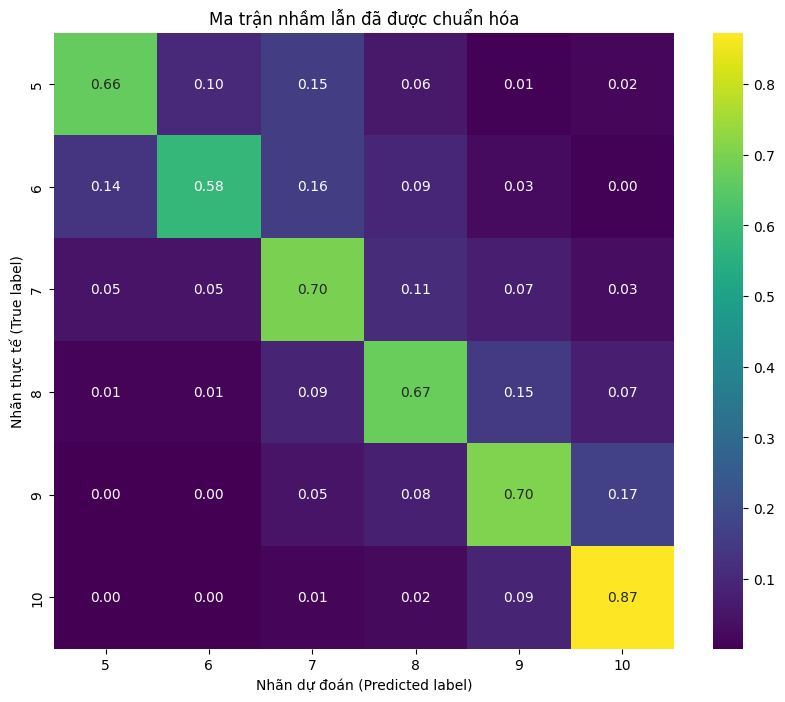

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Giả sử bạn đã có
# test_labels, test_preds là numpy array hoặc list

cm = confusion_matrix(test_labels, test_preds)

# Tên lớp: tùy bạn chọn một trong hai cách
class_names = ['5', '6', '7', '8', '9', '10']           # kiểu điểm số
# class_names = ['Class 0', 'Class 1', 'Class 2', 'Class 3', 'Class 4', 'Class 5']

plt.figure(figsize=(10, 8))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Purples',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 14, "weight": "bold"},
            cbar_kws={'label': 'Số lượng mẫu'})

# Highlight đường chéo
for i in range(len(class_names)):
    plt.gca().add_patch(plt.Rectangle((i, i), 1, 1,
                                      fill=False, edgecolor='red', lw=3.5, zorder=10))

plt.title('Confusion Matrix - Số lượng mẫu thực tế\n', fontsize=16, pad=15)
plt.ylabel('Nhãn thực tế', fontsize=13)
plt.xlabel('Nhãn dự đoán', fontsize=13)
plt.tight_layout()
plt.show()

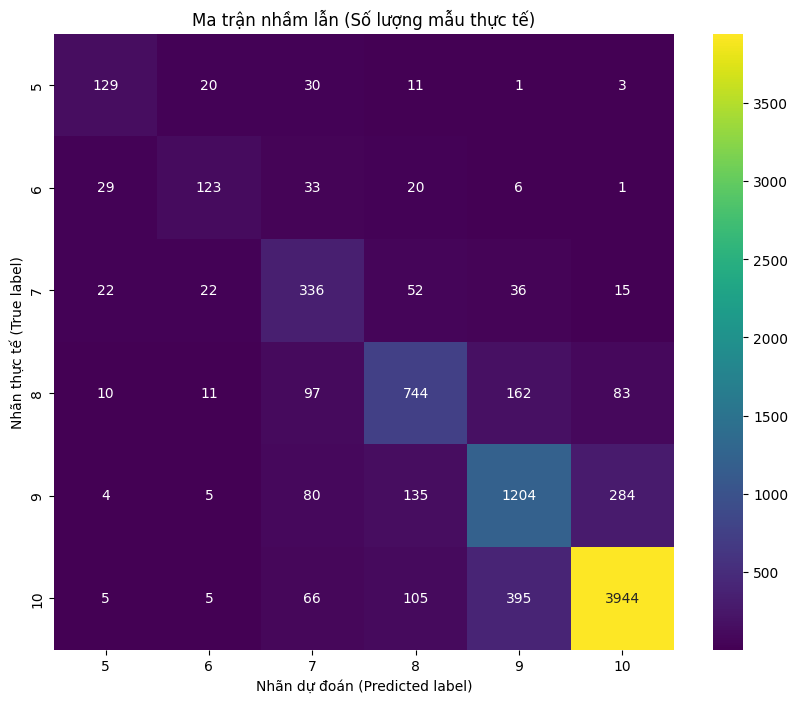

In [ ]:
import numpy as np

cm = confusion_matrix(test_labels, test_preds)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # chuẩn hóa theo hàng

class_names = ['5', '6', '7', '8', '9', '10']

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(cm, annot=False, cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Số lượng'})

# Vẽ text thủ công: số lượng + phần trăm
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        text = f"{cm[i,j]}\n{100*cm_percent[i,j]:.1f}%"
        ax.text(j+0.5, i+0.5, text,
                ha="center", va="center",
                color="white" if cm[i,j] > thresh else "black",
                fontsize=11, fontweight="bold")

ax.set_title("Confusion Matrix\n(Số lượng & % theo hàng thực tế)", fontsize=16, pad=20)
ax.set_ylabel("Nhãn thực tế", fontsize=13)
ax.set_xlabel("Nhãn dự đoán", fontsize=13)

# Đường chéo đỏ
for i in range(len(class_names)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='red', lw=4, zorder=10))

plt.tight_layout()
plt.show()